# COPD 1-mm pTVReg MATLAB vs MR-D-BSCP P2e: displacement-magnitude CDFs

This notebook compares fixed-iBH-lung physical displacement-magnitude distributions for all ten COPD pairs. It uses pTVReg's saved 1-mm `Tptv` field and P2e's saved 1-mm voxel field; because both grids are isotropic 1 mm, vector magnitude is in mm. No registration is run here.

The grids are not always the same shape, so this is a within-case distributional comparison, not a voxelwise field-error calculation. The fixed-iBH lung mask is metric/visualization-only and was not used in either registration objective.

In [1]:
from __future__ import annotations

import os
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PTVREG_ROOT = Path(os.environ['PTVREG_COPD_MATLAB_ROOT'])
P2E_ROOT = Path(os.environ['MRDBSCP_P2E_COPD_ROOT'])
CASES = tuple(range(1, 11))
CHALLENGE_CASE = {case: 103 + case for case in CASES}
MAX_CDF_VOXELS = 200_000
P2E_RUN_TEMPLATE = (
    'direct_cp_32_16_8_4_ptv_lcc_isotv_copd_case{case:02d}_'
    'sched64-32-16-8-4_ds16-8-4-2-1_e400-400-400-400-900_'
    'lr0p001_w0p11_seed1'
)

def summarize_sample(magnitude: np.ndarray) -> tuple[dict[str, float], np.ndarray]:
    values = np.asarray(magnitude, dtype=np.float32).ravel()
    if not np.isfinite(values).all():
        raise ValueError('Displacement magnitude contains non-finite values')
    summary = {
        'sampled grid voxels': int(values.size),
        'mean |u| (mm)': float(values.mean()),
        'median |u| (mm)': float(np.median(values)),
        'p75 |u| (mm)': float(np.percentile(values, 75)),
        'p95 |u| (mm)': float(np.percentile(values, 95)),
        'max |u| (mm)': float(values.max()),
    }
    return summary, np.sort(values)

def read_ptvreg_magnitude(case: int) -> tuple[dict[str, float], np.ndarray, tuple[int, int, int]]:
    path = PTVREG_ROOT / f'case{case:02d}' / f'case{case:02d}_eBH_to_iBH_deformation.mat'
    if not path.is_file():
        raise FileNotFoundError(path)
    with h5py.File(path, 'r') as handle:
        if 'Tptv' not in handle:
            raise ValueError(f'{path}: missing 1-mm Tptv field')
        field = handle['Tptv']
        if field.ndim != 4 or field.shape[0] != 3:
            raise ValueError(f'{path}: expected h5py [3,z,y,x] Tptv, got {field.shape}')
        grid_shape = tuple(field.shape[1:])
        z_step = max(1, int(np.ceil(np.prod(grid_shape) / MAX_CDF_VOXELS)))
        sampled_field = np.asarray(field[:, ::z_step, :, :], dtype=np.float32)
    summary, sample = summarize_sample(np.linalg.norm(sampled_field, axis=0))
    return summary, sample, grid_shape

def read_p2e_magnitude(case: int) -> tuple[dict[str, float], np.ndarray, tuple[int, int, int]]:
    path = P2E_ROOT / P2E_RUN_TEMPLATE.format(case=case) / 'disp_vox_reg1mm_zyx.npy'
    if not path.is_file():
        raise FileNotFoundError(path)
    field = np.load(path, mmap_mode='r')
    if field.ndim != 4 or field.shape[-1] != 3:
        raise ValueError(f'{path}: expected [z,y,x,3] field, got {field.shape}')
    grid_shape = tuple(field.shape[:3])
    z_step = max(1, int(np.ceil(np.prod(grid_shape) / MAX_CDF_VOXELS)))
    sampled_field = np.asarray(field[::z_step], dtype=np.float32)
    summary, sample = summarize_sample(np.linalg.norm(sampled_field, axis=-1))
    return summary, sample, grid_shape

magnitude = {}
summary_rows = []
for case in CASES:
    ptv_summary, ptv_sample, ptv_shape = read_ptvreg_magnitude(case)
    p2e_summary, p2e_sample, p2e_shape = read_p2e_magnitude(case)
    magnitude[case] = {'pTVReg MATLAB': ptv_sample, 'MR-D-BSCP P2e': p2e_sample}
    summary_rows.extend([
        {'COPD case': f'COPD{case}', 'Challenge case': CHALLENGE_CASE[case], 'method': 'pTVReg MATLAB', 'grid shape [z,y,x]': ptv_shape, **ptv_summary},
        {'COPD case': f'COPD{case}', 'Challenge case': CHALLENGE_CASE[case], 'method': 'MR-D-BSCP P2e', 'grid shape [z,y,x]': p2e_shape, **p2e_summary},
    ])

summary = pd.DataFrame(summary_rows).set_index(['COPD case', 'method']).sort_index()
summary.round(3)
None  # The fixed-lung summary below is the review result.


The fixed-lung table and plotted CDFs use deterministic z-stride samples of at most roughly 200,000 registration-grid voxels per method and case. P2e uses the canonical fixed-iBH mask directly (exact grid match); MATLAB pTVReg uses that same canonical mask nearest-resampled only when its saved `Tptv` z size differs. This is a metric/visualization alignment, not an optimization-domain change.

In [2]:
PTVREG_ISO1MM_COPD_ROOT = Path(os.environ['PTVREG_ISO1MM_COPD_ROOT'])


def nearest_resample_mask_zyx(mask_zyx: np.ndarray, target_shape: tuple[int, int, int]) -> np.ndarray:
    """PyTorch-nearest-equivalent index mapping, expressed explicitly for audit."""
    if mask_zyx.shape == target_shape:
        return mask_zyx.astype(bool, copy=False)
    indices = tuple(
        np.minimum((np.arange(target) * source // target).astype(np.intp), source - 1)
        for source, target in zip(mask_zyx.shape, target_shape)
    )
    return mask_zyx[np.ix_(*indices)].astype(bool, copy=False)


def fixed_lung_on_field_grid(case: int, target_shape: tuple[int, int, int]) -> tuple[np.ndarray, str]:
    path = PTVREG_ISO1MM_COPD_ROOT / f'case{case:02d}' / 'fixed_iBH_lungmask_reg1mm_nearest_zyx.npy'
    if not path.is_file():
        raise FileNotFoundError(path)
    canonical = np.load(path).astype(bool, copy=False)
    if not canonical.any():
        raise ValueError(f'Empty fixed-iBH lung mask: {path}')
    if canonical.shape == target_shape:
        return canonical, 'exact canonical fixed-iBH mask'
    return (
        nearest_resample_mask_zyx(canonical, target_shape),
        f'nearest resampled canonical mask {canonical.shape} -> {target_shape}',
    )


def summarize_lung_sample(magnitude_zyx: np.ndarray, fixed_lung_zyx: np.ndarray) -> tuple[dict[str, float], np.ndarray]:
    values = np.asarray(magnitude_zyx[fixed_lung_zyx], dtype=np.float32)
    if values.size == 0 or not np.isfinite(values).all():
        raise ValueError('Fixed-lung displacement magnitudes must be finite and non-empty')
    summary = {
        'sampled fixed-lung voxels': int(values.size),
        'mean |u| (mm)': float(values.mean()),
        'median |u| (mm)': float(np.median(values)),
        'p75 |u| (mm)': float(np.percentile(values, 75)),
        'p95 |u| (mm)': float(np.percentile(values, 95)),
        'max |u| (mm)': float(values.max()),
    }
    return summary, np.sort(values)


def read_ptvreg_fixed_lung_magnitude(case: int) -> tuple[dict[str, float], np.ndarray, tuple[int, int, int], str]:
    path = PTVREG_ROOT / f'case{case:02d}' / f'case{case:02d}_eBH_to_iBH_deformation.mat'
    with h5py.File(path, 'r') as handle:
        field = handle['Tptv']
        target_shape = tuple(field.shape[1:])
        fixed_lung, alignment = fixed_lung_on_field_grid(case, target_shape)
        z_step = max(1, int(np.ceil(np.prod(target_shape) / MAX_CDF_VOXELS)))
        sampled_field = np.asarray(field[:, ::z_step, :, :], dtype=np.float32)
    return (*summarize_lung_sample(np.linalg.norm(sampled_field, axis=0), fixed_lung[::z_step]), target_shape, alignment)


def read_p2e_fixed_lung_magnitude(case: int) -> tuple[dict[str, float], np.ndarray, tuple[int, int, int], str]:
    path = P2E_ROOT / P2E_RUN_TEMPLATE.format(case=case) / 'disp_vox_reg1mm_zyx.npy'
    field = np.load(path, mmap_mode='r')
    target_shape = tuple(field.shape[:3])
    fixed_lung, alignment = fixed_lung_on_field_grid(case, target_shape)
    z_step = max(1, int(np.ceil(np.prod(target_shape) / MAX_CDF_VOXELS)))
    sampled_field = np.asarray(field[::z_step], dtype=np.float32)
    return (*summarize_lung_sample(np.linalg.norm(sampled_field, axis=-1), fixed_lung[::z_step]), target_shape, alignment)


magnitude = {}
summary_rows = []
for case in CASES:
    ptv_summary, ptv_sample, ptv_shape, ptv_alignment = read_ptvreg_fixed_lung_magnitude(case)
    p2e_summary, p2e_sample, p2e_shape, p2e_alignment = read_p2e_fixed_lung_magnitude(case)
    magnitude[case] = {'pTVReg MATLAB': ptv_sample, 'MR-D-BSCP P2e': p2e_sample}
    summary_rows.extend([
        {'COPD case': f'COPD{case}', 'Challenge case': CHALLENGE_CASE[case], 'method': 'pTVReg MATLAB', 'field grid [z,y,x]': ptv_shape, 'fixed-lung alignment': ptv_alignment, **ptv_summary},
        {'COPD case': f'COPD{case}', 'Challenge case': CHALLENGE_CASE[case], 'method': 'MR-D-BSCP P2e', 'field grid [z,y,x]': p2e_shape, 'fixed-lung alignment': p2e_alignment, **p2e_summary},
    ])

summary = pd.DataFrame(summary_rows).set_index(['COPD case', 'method']).sort_index()
summary.round(3)


Challenge case field grid [z,y,x]  \
COPD case method                                             
COPD1     MR-D-BSCP P2e             104    (275, 201, 229)   
          pTVReg MATLAB             104    (273, 201, 229)   
COPD10    MR-D-BSCP P2e             113    (232, 212, 298)   
          pTVReg MATLAB             113    (233, 212, 298)   
COPD2     MR-D-BSCP P2e             105    (215, 197, 246)   
          pTVReg MATLAB             105    (215, 197, 246)   
COPD3     MR-D-BSCP P2e             106    (252, 188, 264)   
          pTVReg MATLAB             106    (253, 188, 264)   
COPD4     MR-D-BSCP P2e             107    (252, 173, 233)   
          pTVReg MATLAB             107    (253, 173, 233)   
COPD5     MR-D-BSCP P2e             108    (262, 193, 248)   
          pTVReg MATLAB             108    (263, 193, 248)   
COPD6     MR-D-BSCP P2e             109    (252, 180, 246)   
          pTVReg MATLAB             109    (253, 180, 246)   
COPD7     MR-D-BSCP P2e             110    (255, 167, 251)   
          pTVReg MATLAB             110    (255, 167, 251)   
COPD8     MR-D-BSCP P2e             111    (250, 175, 240)   
          pTVReg MATLAB             111    (250, 175, 240)   
COPD9     MR-D-BSCP P2e             112    (240, 191, 264)   
          pTVReg MATLAB             112    (240, 191, 264)   

                                                      fixed-lung alignment  \
COPD case method                                                             
COPD1     MR-D-BSCP P2e                     exact canonical fixed-iBH mask   
          pTVReg MATLAB  nearest resampled canonical mask (275, 201, 22...   
COPD10    MR-D-BSCP P2e                     exact canonical fixed-iBH mask   
          pTVReg MATLAB  nearest resampled canonical mask (232, 212, 29...   
COPD2     MR-D-BSCP P2e                     exact canonical fixed-iBH mask   
          pTVReg MATLAB                     exact canonical fixed-iBH mask   
COPD3     MR-D-BSCP P2e                     exact canonical fixed-iBH mask   
          pTVReg MATLAB  nearest resampled canonical mask (252, 188, 26...   
COPD4     MR-D-BSCP P2e                     exact canonical fixed-iBH mask   
          pTVReg MATLAB  nearest resampled canonical mask (252, 173, 23...   
COPD5     MR-D-BSCP P2e                     exact canonical fixed-iBH mask   
          pTVReg MATLAB  nearest resampled canonical mask (262, 193, 24...   
COPD6     MR-D-BSCP P2e                     exact canonical fixed-iBH mask   
          pTVReg MATLAB  nearest resampled canonical mask (252, 180, 24...   
COPD7     MR-D-BSCP P2e                     exact canonical fixed-iBH mask   
          pTVReg MATLAB                     exact canonical fixed-iBH mask   
COPD8     MR-D-BSCP P2e                     exact canonical fixed-iBH mask   
          pTVReg MATLAB                     exact canonical fixed-iBH mask   
COPD9     MR-D-BSCP P2e                     exact canonical fixed-iBH mask   
          pTVReg MATLAB                     exact canonical fixed-iBH mask   

                         sampled fixed-lung voxels  mean |u| (mm)  \
COPD case method                                                    
COPD1     MR-D-BSCP P2e                     103369         27.761   
          pTVReg MATLAB                     106002         28.278   
COPD10    MR-D-BSCP P2e                      87761         21.240   
          pTVReg MATLAB                      87848         21.186   
COPD2     MR-D-BSCP P2e                      75947         17.967   
          pTVReg MATLAB                      75947         19.888   
COPD3     MR-D-BSCP P2e                      71100         12.652   
          pTVReg MATLAB                      77532         13.297   
COPD4     MR-D-BSCP P2e                      79963         31.893   
          pTVReg MATLAB                      80063         31.536   
COPD5     MR-D-BSCP P2e                      82422         33.637   
          pTVReg MATLAB                      8

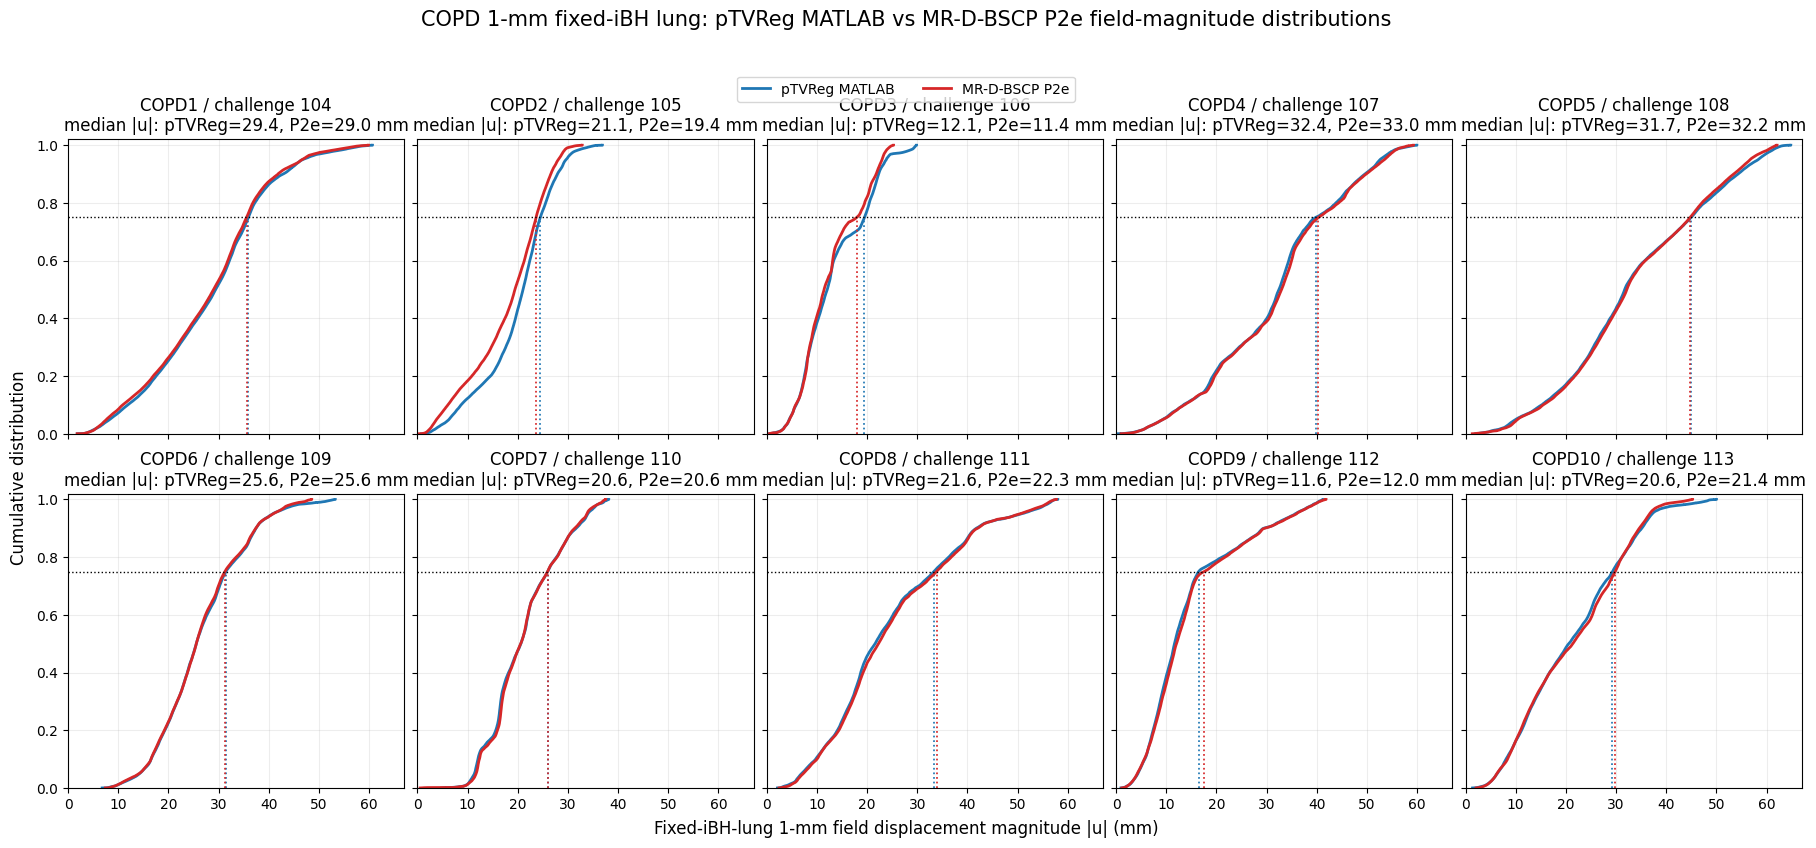

In [3]:
COLORS = {'pTVReg MATLAB': '#1f77b4', 'MR-D-BSCP P2e': '#d62728'}
Q = 0.75
xmax = float(np.ceil(max(values[-1] for method_values in magnitude.values() for values in method_values.values()) * 1.03))

fig, axes = plt.subplots(2, 5, figsize=(18, 7.5), sharex=True, sharey=True, constrained_layout=True)
for axis, case in zip(axes.flat, CASES):
    for method, values in magnitude[case].items():
        cdf = np.arange(1, len(values) + 1) / len(values)
        p75 = np.percentile(values, 75)
        axis.step(values, cdf, where='post', color=COLORS[method], lw=2.0, label=method)
        axis.vlines(p75, 0, Q, color=COLORS[method], ls=':', lw=1.25)
    axis.axhline(Q, color='black', ls=':', lw=1.0)
    ptv_median = summary.loc[(f'COPD{case}', 'pTVReg MATLAB'), 'median |u| (mm)']
    p2e_median = summary.loc[(f'COPD{case}', 'MR-D-BSCP P2e'), 'median |u| (mm)']
    axis.set_title(f'COPD{case} / challenge {CHALLENGE_CASE[case]}\nmedian |u|: pTVReg={ptv_median:.1f}, P2e={p2e_median:.1f} mm')
    axis.set(xlim=(0, xmax), ylim=(0, 1.02))
    axis.grid(alpha=0.22)

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=2, frameon=True, bbox_to_anchor=(0.5, 1.03))
fig.supxlabel('Fixed-iBH-lung 1-mm field displacement magnitude |u| (mm)')
fig.supylabel('Cumulative distribution')
fig.suptitle('COPD 1-mm fixed-iBH lung: pTVReg MATLAB vs MR-D-BSCP P2e field-magnitude distributions', y=1.11, fontsize=15)
plt.show()


## Fixed-lung coronal displacement-magnitude views

The rendered panels use the reference notebook's radiology convention. The saved COPD fields are raw `z,y,x`, so the documented reference-lineage conversion is applied first: `z' = Nz - 1 - z`, then `zyx -> xyz`, coronal extraction, transpose, left-right flip, and `origin='lower'`. Each plane is chosen at the median y index of its fixed-iBH lung mask, displays only fixed-lung magnitude, and overlays the fixed-lung boundary in cyan. Each five-case block has a pTVReg row followed by a P2e row.

In [4]:
def coronal_radiology(plane_zx: np.ndarray) -> np.ndarray:
    return np.fliplr(np.asarray(plane_zx).T)


def read_ptvreg_coronal(case: int) -> tuple[np.ndarray, int, tuple[int, int, int]]:
    path = PTVREG_ROOT / f'case{case:02d}' / f'case{case:02d}_eBH_to_iBH_deformation.mat'
    with h5py.File(path, 'r') as handle:
        field = handle['Tptv']
        grid_shape = tuple(field.shape[1:])
        y_index = (grid_shape[1] - 1) // 2
        coronal_field = np.asarray(field[:, :, y_index, :], dtype=np.float32)
    return np.linalg.norm(coronal_field, axis=0), y_index, grid_shape


def read_p2e_coronal(case: int) -> tuple[np.ndarray, int, tuple[int, int, int]]:
    path = P2E_ROOT / P2E_RUN_TEMPLATE.format(case=case) / 'disp_vox_reg1mm_zyx.npy'
    field = np.load(path, mmap_mode='r')
    grid_shape = tuple(field.shape[:3])
    y_index = (grid_shape[1] - 1) // 2
    coronal_field = np.asarray(field[:, y_index, :, :], dtype=np.float32)
    return np.linalg.norm(coronal_field, axis=-1), y_index, grid_shape


coronal = {}
for case in CASES:
    ptv_plane, ptv_y, ptv_shape = read_ptvreg_coronal(case)
    p2e_plane, p2e_y, p2e_shape = read_p2e_coronal(case)
    coronal[case] = {
        'pTVReg MATLAB': (ptv_plane, ptv_y, ptv_shape),
        'MR-D-BSCP P2e': (p2e_plane, p2e_y, p2e_shape),
    }

vmax_coronal = float(np.percentile(
    np.concatenate([plane.ravel() for case_planes in coronal.values() for plane, _, _ in case_planes.values()]),
    99,
))

fig, axes = plt.subplots(4, 5, figsize=(18, 13.8), constrained_layout=True)
for case_index, case in enumerate(CASES):
    block = case_index // 5
    column = case_index % 5
    ptv_y = coronal[case]['pTVReg MATLAB'][1]
    p2e_y = coronal[case]['MR-D-BSCP P2e'][1]
    for method_index, method in enumerate(COLORS):
        row = 2 * block + method_index
        axis = axes[row, column]
        plane, y_index, grid_shape = coronal[case][method]
        image = axis.imshow(
            coronal_radiology(plane), cmap='magma', origin='lower',
            vmin=0, vmax=vmax_coronal, aspect='equal',
        )
        if method_index == 0:
            axis.set_title(f'COPD{case} / challenge {CHALLENGE_CASE[case]}\ncenter y: pTV={ptv_y}, P2e={p2e_y}')
        if column == 0:
            axis.set_ylabel(method)
        axis.set_xticks([])
        axis.set_yticks([])

fig.colorbar(image, ax=axes, shrink=0.84, label='Displacement magnitude |u| (mm)')
fig.suptitle(
    f'COPD 1-mm centered coronal field magnitude — shared 99th-percentile scale (0–{vmax_coronal:.1f} mm)',
    fontsize=15,
)
plt.close(fig)  # Superseded below by fixed-lung, orientation-marked coronal maps.


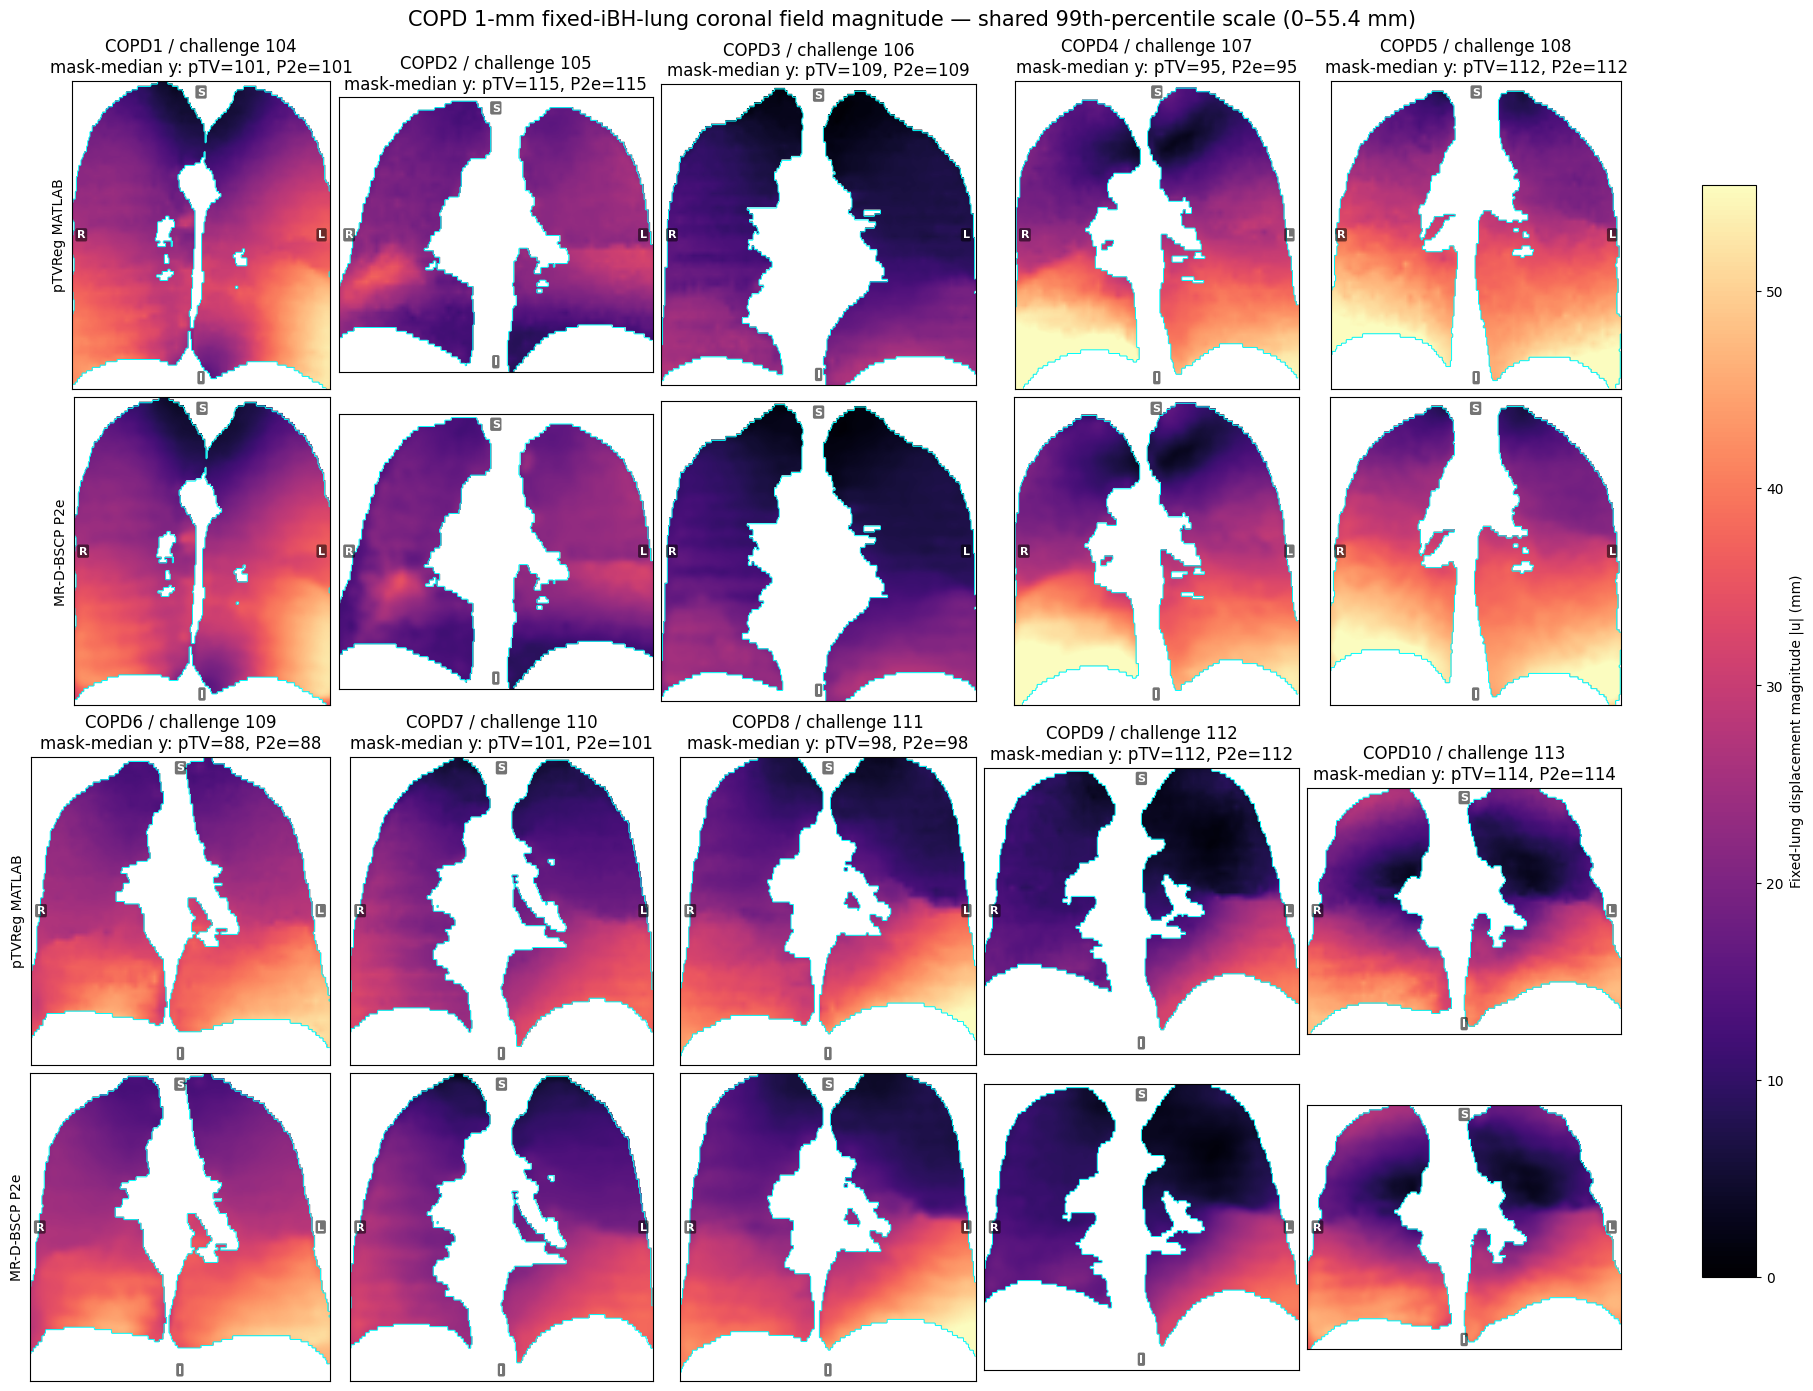

In [5]:
def coronal_radiology(array_zyx: np.ndarray, y_index: int) -> np.ndarray:
    # COPD raw storage is z,y,x. The reference lineage is zyx -> xyz with raw z reversed.
    # This is the documented raw_original_to_postflip_xyz transform: z' = Nz - 1 - z.
    array_xyz = np.transpose(np.asarray(array_zyx)[::-1, :, :], (2, 1, 0))
    return np.fliplr(array_xyz[:, int(y_index), :].T)


def orientation_markers(axis) -> None:
    style = dict(
        transform=axis.transAxes, color='white', fontsize=8, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.15', facecolor='black', alpha=0.55, edgecolor='none'),
    )
    axis.text(0.50, 0.98, 'S', ha='center', va='top', **style)
    axis.text(0.50, 0.02, 'I', ha='center', va='bottom', **style)
    axis.text(0.02, 0.50, 'R', ha='left', va='center', **style)
    axis.text(0.98, 0.50, 'L', ha='right', va='center', **style)


def read_ptvreg_fixed_lung_coronal(case: int) -> dict[str, object]:
    path = PTVREG_ROOT / f'case{case:02d}' / f'case{case:02d}_eBH_to_iBH_deformation.mat'
    with h5py.File(path, 'r') as handle:
        field = handle['Tptv']
        grid_shape = tuple(field.shape[1:])
        fixed_lung, alignment = fixed_lung_on_field_grid(case, grid_shape)
        y_index = int(np.median(np.where(fixed_lung)[1]))
        coronal_field = np.asarray(field[:, :, y_index, :], dtype=np.float32)
    return {
        'magnitude': np.linalg.norm(coronal_field, axis=0),
        'fixed_lung': fixed_lung[:, y_index, :],
        'y_index': y_index,
        'grid_shape': grid_shape,
        'alignment': alignment,
    }


def read_p2e_fixed_lung_coronal(case: int) -> dict[str, object]:
    path = P2E_ROOT / P2E_RUN_TEMPLATE.format(case=case) / 'disp_vox_reg1mm_zyx.npy'
    field = np.load(path, mmap_mode='r')
    grid_shape = tuple(field.shape[:3])
    fixed_lung, alignment = fixed_lung_on_field_grid(case, grid_shape)
    y_index = int(np.median(np.where(fixed_lung)[1]))
    coronal_field = np.asarray(field[:, y_index, :, :], dtype=np.float32)
    return {
        'magnitude': np.linalg.norm(coronal_field, axis=-1),
        'fixed_lung': fixed_lung[:, y_index, :],
        'y_index': y_index,
        'grid_shape': grid_shape,
        'alignment': alignment,
    }


coronal = {}
for case in CASES:
    coronal[case] = {
        'pTVReg MATLAB': read_ptvreg_fixed_lung_coronal(case),
        'MR-D-BSCP P2e': read_p2e_fixed_lung_coronal(case),
    }

all_lung_magnitudes = np.concatenate([
    panel['magnitude'][panel['fixed_lung']]
    for case_panels in coronal.values()
    for panel in case_panels.values()
])
vmax_coronal = float(np.percentile(all_lung_magnitudes, 99))

fig, axes = plt.subplots(4, 5, figsize=(18, 13.8), constrained_layout=True)
for case_index, case in enumerate(CASES):
    block = case_index // 5
    column = case_index % 5
    ptv_y = coronal[case]['pTVReg MATLAB']['y_index']
    p2e_y = coronal[case]['MR-D-BSCP P2e']['y_index']
    for method_index, method in enumerate(COLORS):
        row = 2 * block + method_index
        axis = axes[row, column]
        panel = coronal[case][method]
        masked_magnitude = np.where(panel['fixed_lung'], panel['magnitude'], np.nan)
        image = axis.imshow(
            coronal_radiology(masked_magnitude[:, None, :], 0), cmap='magma', origin='lower',
            vmin=0, vmax=vmax_coronal, aspect='equal',
        )
        axis.contour(
            coronal_radiology(panel['fixed_lung'].astype(float)[:, None, :], 0),
            levels=[0.5], colors='cyan', linewidths=0.7,
        )
        if method_index == 0:
            axis.set_title(f'COPD{case} / challenge {CHALLENGE_CASE[case]}\nmask-median y: pTV={ptv_y}, P2e={p2e_y}')
        if column == 0:
            axis.set_ylabel(method)
        axis.set_xticks([])
        axis.set_yticks([])
        orientation_markers(axis)

fig.colorbar(image, ax=axes, shrink=0.84, label='Fixed-lung displacement magnitude |u| (mm)')
fig.suptitle(
    f'COPD 1-mm fixed-iBH-lung coronal field magnitude — shared 99th-percentile scale (0–{vmax_coronal:.1f} mm)',
    fontsize=15,
)
plt.show()


A curve farther left has lower displacement magnitude within the fixed-iBH lung. Interpret this together with the TRE CDFs: lower magnitude is not automatically better if it underfits landmark motion. The fixed-iBH mask is metric/visualization-only, not part of either registration objective. P2e uses its exact canonical 1-mm mask grid; when MATLAB `Tptv` has a different z size, the notebook explicitly nearest-resamples the same canonical mask for foreground comparison.